# ASB Case Study 7A - Image Classification with CIFAR-10

Note: This notebook was run in a cloud environment (Google Colab)

In [1]:
from pathlib import Path
import shutil
import pickle
import tarfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras

# from google.colab import driveb
# drive.mount("/content/drive")

## 0 - Preliminaries

- The following code is completely optional. The function should work normally under the hood as it is.
- This approach was done to bypass slow download progress within the function.

In [2]:
# !mkdir -p ~/.keras/datasets
# !wget https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz -O ~/.keras/datasets/cifar-10-batches-py.tar.gz

In [2]:
drive_path = Path("/content/drive/MyDrive/devspace/asb-cs7/cifar-10-python.tar.gz")
keras_cache_dir = Path("~/.keras/datasets").expanduser()
keras_cache_dir.mkdir(parents=True, exist_ok=True)

dest_path = keras_cache_dir / "cifar-10-batches-py.tar.gz"
shutil.copy2(drive_path, dest_path)

PosixPath('/root/.keras/datasets/cifar-10-batches-py.tar.gz')

In [3]:
def _load_batch(fpath: Path, label_key: str = "labels"):
    """Internal utility for parsing a single CIFAR batch file."""
    with fpath.open("rb") as f:
        d = pickle.load(f, encoding="bytes")
        # Decode byte keys to strings
        d_decoded = {k.decode("utf8"): v for k, v in d.items()}

    data = d_decoded["data"]
    labels = d_decoded[label_key]

    data = data.reshape(data.shape[0], 3, 32, 32)
    return data, labels


def load_cifar10(
    archive_path: str | Path = "~/.keras/datasets/cifar-10-batches-py.tar.gz",
):
    """Loads the CIFAR-10 dataset from a local .tar.gz archive."""
    archive_path = Path(archive_path).expanduser().resolve()
    extract_dir = archive_path.parent
    batches_dir = extract_dir / "cifar-10-batches-py"

    # Extract the archive only if the folder doesn't already exist
    if not batches_dir.exists():
        if not archive_path.exists():
            raise FileNotFoundError(f"Dataset archive not found at: {archive_path}")
        with tarfile.open(archive_path, "r:gz") as tar:
            tar.extractall(path=extract_dir, filter="data")

    num_train_samples = 50000
    x_train = np.empty((num_train_samples, 3, 32, 32), dtype="uint8")
    y_train = np.empty((num_train_samples,), dtype="uint8")

    for i in range(1, 6):
        fpath = batches_dir / f"data_batch_{i}"
        (
            x_train[(i - 1) * 10000 : i * 10000, :, :, :],
            y_train[(i - 1) * 10000 : i * 10000],
        ) = _load_batch(fpath)

    x_test, y_test = _load_batch(batches_dir / "test_batch")

    y_train = np.reshape(y_train, (len(y_train), 1))
    y_test = np.reshape(y_test, (len(y_test), 1))

    if tf.keras.backend.image_data_format() == "channels_last":
        x_train = x_train.transpose(0, 2, 3, 1)
        x_test = x_test.transpose(0, 2, 3, 1)

    x_test = x_test.astype(x_train.dtype)
    y_test = y_test.astype(y_train.dtype)

    return (x_train, y_train), (x_test, y_test)

## 1 - Data ingestion and representation

In [4]:
# (X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()
(X_train, y_train), (X_test, y_test) = load_cifar10()

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((50000, 32, 32, 3), (50000, 1), (10000, 32, 32, 3), (10000, 1))

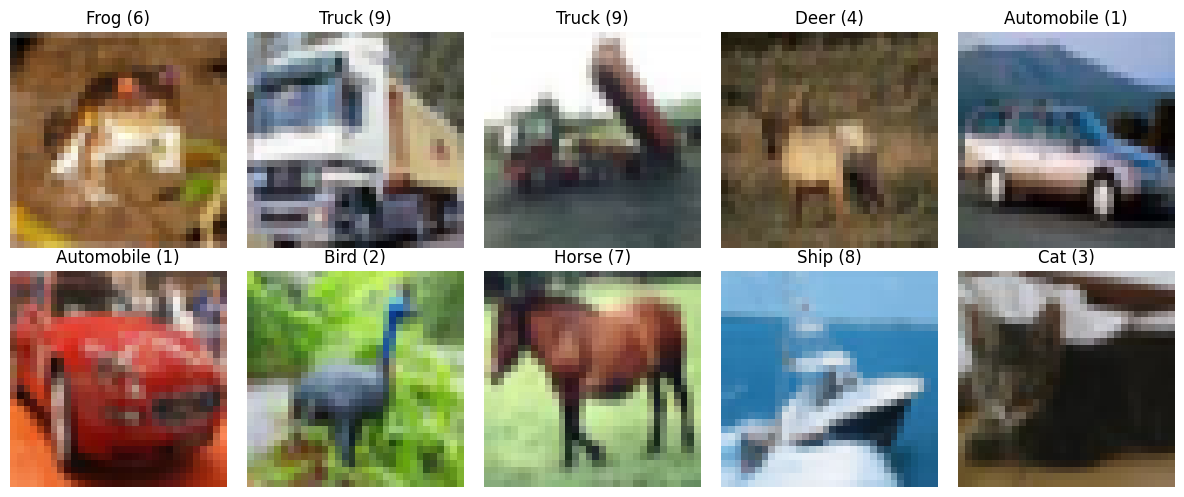

In [5]:
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Visualize 10 sample images
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    # y_train[i] is an array like [6], so we index [0] to get the integer
    label_index = y_train[i][0]
    plt.title(f"{class_names[label_index]} ({label_index})")
    plt.axis("off")
plt.tight_layout()

Dimension Breakdown (50000, 32, 32, 3)

- 50000 -> Batch/sample axis (number of training images)
- 32, 32 -> Spatial axes (height and width in pixels)
- 3 -> Channel axis (Red, Green, and Blue intensity layers stacked together)

In [6]:
# Pixel normalization
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

## 2 - Architecture design and compilation

In [7]:
model = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),

    # Block 1: Low-level feature extraction
    keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Block 2: Higher-level feature combination
    keras.layers.Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification head
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Compiling the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 4 - Model training and evaluation

### 4.1 - Training

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 81s 113ms/step - accuracy: 0.4374 - loss: 1.5625 - val_accuracy: 0.5534 - val_loss: 1.2639
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 81s 112ms/step - accuracy: 0.5804 - loss: 1.1860 - val_accuracy: 0.6340 - val_loss: 1.0312
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 81s 111ms/step - accuracy: 0.6272 - loss: 1.0608 - val_accuracy: 0.6672 - val_loss: 0.9501
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 78s 111ms/step - accuracy: 0.6532 - loss: 0.9734 - val_accuracy: 0.6828 - val_loss: 0.9102
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 85s 116ms/step - accuracy: 0.6809 - loss: 0.9049 - val_accuracy: 0.6922 - val_loss: 0.8981
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 83s 118ms/step - accuracy: 0.7028 - loss: 0.8469 - val_accuracy: 0.7004 - val_loss: 0.8678
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 84s 119ms/step - accuracy: 0.7212 - loss: 0.7907 - val_accuracy: 0.7082 - val_loss: 0.8464
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 88s 125ms/step - accuracy: 0.7371 - loss: 0

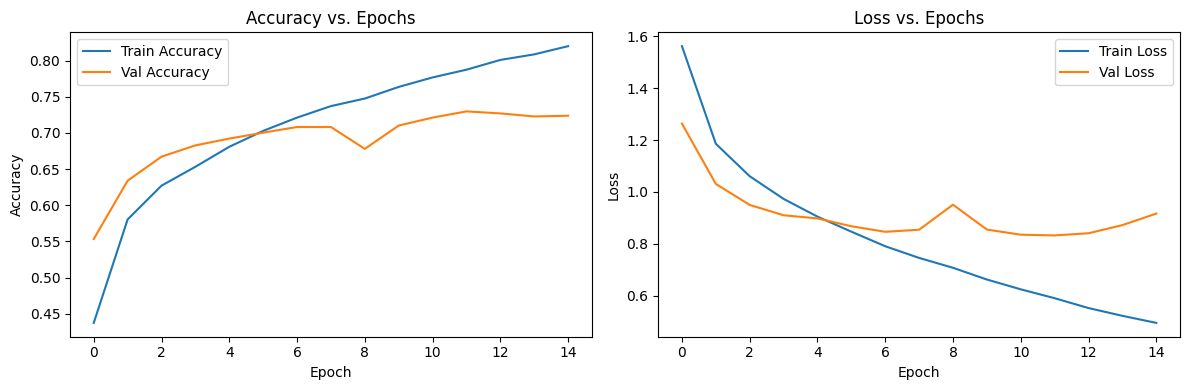

In [9]:
history = model.fit(
    X_train,
    y_train,
    # Holds out 5,000 images for per-epoch validation
    validation_split=0.1,
    epochs=15,
    batch_size=64
)

# Plotting learning curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history["accuracy"], label="Train Accuracy")
ax1.plot(history.history["val_accuracy"], label="Val Accuracy")
ax1.set_title("Accuracy vs. Epochs")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.legend()

ax2.plot(history.history["loss"], label="Train Loss")
ax2.plot(history.history["val_loss"], label="Val Loss")
ax2.set_title("Loss vs. Epochs")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()

plt.tight_layout()

Remarks:

- The model do improve as epoch increases. We can notice a steady increase in the training accuracy, and the same goes with validation accuracy in the first 7 epochs.
- There's a sign of overfitting after epoch 7. Notice that the training accuracy still increases while the validation accuracy dips a little at epoch 8 and then practically plateau in the succeeding epochs. Notice as well the validation loss generally goes up epoch 7.
- The widening gap between training accuracy and validation accuracy indicates the network is memorizing training image noise rather than learning generalizable features.

### 4.2 - Test evaluation

Baseline Test Accuracy: 0.7105
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step


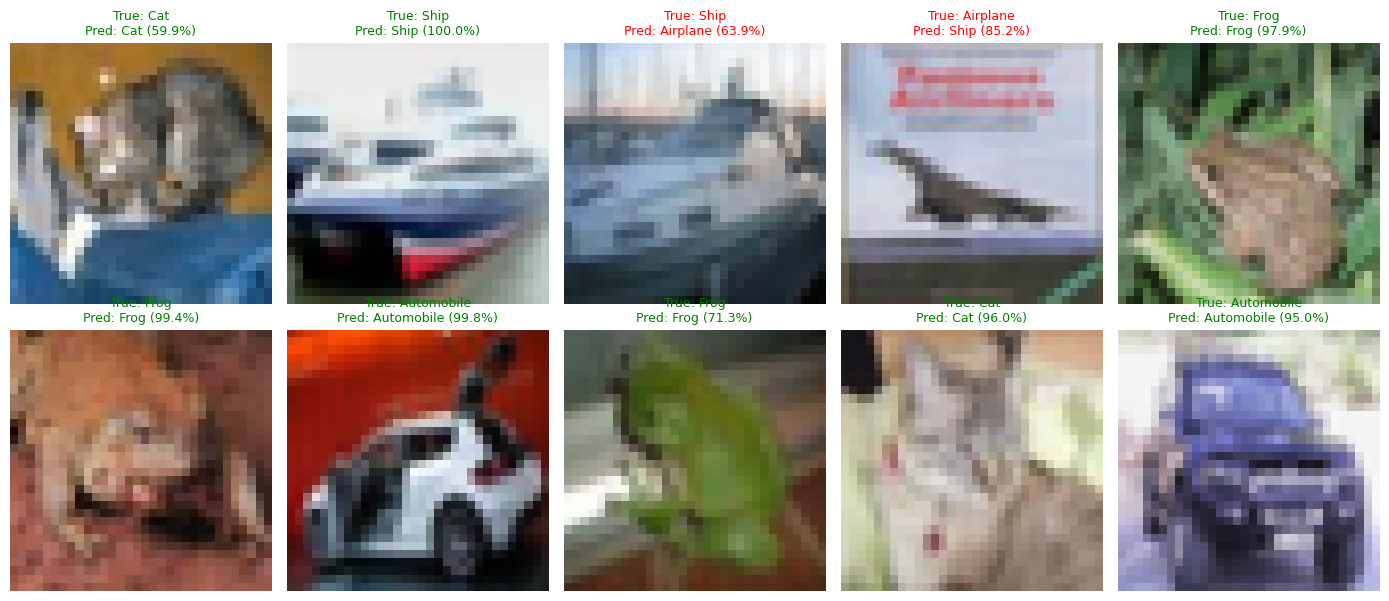

In [10]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Baseline Test Accuracy: {test_accuracy:.4f}")

# Inspecting individual predictions
predictions = model.predict(X_test[:10])

plt.figure(figsize=(14, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])
    pred_idx = np.argmax(predictions[i])
    true_idx = y_test[i][0]
    confidence = np.max(predictions[i]) * 100

    color = "green" if pred_idx == true_idx else "red"
    plt.title(
        f"True: {class_names[true_idx]}\nPred: {class_names[pred_idx]} ({confidence:.1f}%)",
        color=color,
        fontsize=9
    )
    plt.axis("off")
plt.tight_layout()

At 32 x 32 resolution, the images are quite blurry. Common misclassifications such as confusing a cat with a dog, a deer with a horse, or an automobile with a truck, which make visual sense because those pairs share similar silhouettes, textures, and backgrounds (e.g. green grass for deer/horses, gray asphalt for cars/trucks).

## 5 - Experimentation

In the baseline model, we encounter two issues.

- Limited depth (only two convolutional blocks to capture complex object parts)   
- Overfitting after epoch 7

For modifications, consider the following so that the network learns richer hierarchical features without over-training.

- Adding a 3rd Conv2D + MaxPooling block with 128 filters
- Early Stopping

In [11]:
model_rev = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),

    keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    keras.layers.MaxPooling2D((2, 2)),

    # New block 3: Captures higher-level combinations (e.g., wheels, wings, faces)
    keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10, activation="softmax")
])

model_rev.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_mod = model_rev.fit(
    X_train,
    y_train,
    validation_split=0.1,
    # Higher ceiling, letting early stopping decide when to halt
    epochs=20,
    batch_size=64,
    callbacks=[early_stopping]
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 111s 156ms/step - accuracy: 0.4244 - loss: 1.5806 - val_accuracy: 0.5774 - val_loss: 1.1776
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 143s 158ms/step - accuracy: 0.5801 - loss: 1.1795 - val_accuracy: 0.6474 - val_loss: 1.0024
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 108s 154ms/step - accuracy: 0.6494 - loss: 0.9970 - val_accuracy: 0.7138 - val_loss: 0.8324
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 144s 156ms/step - accuracy: 0.6899 - loss: 0.8779 - val_accuracy: 0.7206 - val_loss: 0.8014
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 108s 153ms/step - accuracy: 0.7241 - loss: 0.7894 - val_accuracy: 0.7300 - val_loss: 0.7862
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 110s 157ms/step - accuracy: 0.7508 - loss: 0.7155 - val_accuracy: 0.7558 - val_loss: 0.7278
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 139s 153ms/step - accuracy: 0.7698 - loss: 0.6587 - val_accuracy: 0.7582 - val_loss: 0.7220
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 142s 154ms/step - accuracy: 0.7889 -

In [13]:
mod_loss, mod_accuracy = model_rev.evaluate(X_test, y_test, verbose=0)
print(f"Modified Test Accuracy: {mod_accuracy:.4f}")

Modified Test Accuracy: 0.7428


| Model | Architecture/Change | Test Accuracy |
| --- | --- | --- |
| Baseline CNN | 32 → 64 filters + Dense(128) | 0.7105 |
| Modified CNN | 32 → 64 → 128 filters + 3rd MaxPool + EarlyStopping | 0.7428 |

Remarks:

Notice a counterintuitive property of CNNs: adding a third convolutional block decreased total model parameters while improving test accuracy. Because the extra MaxPooling2D layer reduced the spatial grid from 8 x 8 down to 4 x 4 before flattening (4 x 4 x 128 = 2,048 inputs instead of 4,096), the massive Dense layer required half as many weights, reducing overfitting while boosting representational power.

## 6 - Discussion

- Transformation through Conv/Pool layers: Spatial dimensions shrink (32×32 → 16×16 → 8×8) while channel depth grows (3 → 32 → 64), converting raw pixel grids into compact, abstract feature maps.
- What the CNN learned: Early layers detected basic edges and color contrasts; deeper layers combined them into object parts (wheels, wings, animal silhouettes).
- Architecture change: Added a third Conv2D(128) + MaxPooling2D block and EarlyStopping to the baseline.
- Effect of change: Parameter count dropped due to smaller flattened dimensions, overfitting was curbed, and test accuracy improved by about 3%.
- Unlike tabular models where feature engineering happens before training, CNNs learn spatial features directly, and smaller, deeper architectures often generalize better than wide, shallow ones.